# Systemy inspekcji wizualnej  
## Laboratorium  4 
Temat: Filtracja obrazów i wykrywanie krawędzi

Instrukcję opracował: dr inż. Łukasz Jeleń  
  
Wrocław 2026

---

Nazwisko i Imię: Aleksander Łyskawa  
Nr albumu:  275462   
data wykonania ćwiczenia: 10.11.2026    

---

# 1. Narzędzia  
  
  
Na zjęciach korzystamy z pythnona, a jako środowisko pracy mają Państwo do wyboru Google Colab (https://colab.research.google.com) - wersja online, lub Anaconda Navigator (https://www.anaconda.com/) - wymaga instalacji na własnym komputerze. Są to oczywiście tylko propozycje. 

# 2. Zadania. 
  
## Zadanie 1 - Dodawanie szumu do obrazów. 
  

Do zadania należy wykorzystać obraz testowy stworzony w trakcie laboratorium 2 (ten z paskami) oraz po 1 obrazie tarczy z laboratorium 3 (jedna sprawna, druga wadliwa). 
Obrazy zamień na obrazy monochromatyczne (jeśli jest taka potrzeba) oraz wykonaj poniższe polecenia. 

Paski: (238, 225), uint8, zakres 10-190
OK: (300, 300), uint8, zakres 0-250
NOK: (300, 300), uint8, zakres 0-255


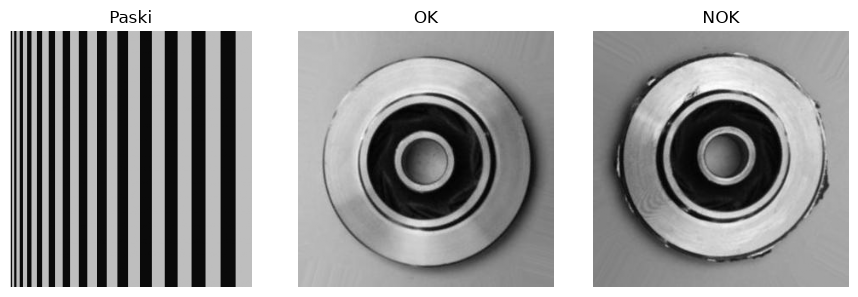

In [18]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt


rng = np.random.default_rng(275462)

def load(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Nie mozna wczytac: {path}")
    return img


def show(imgs, titles):
    fig, axes = plt.subplots(
        1, len(imgs), figsize=(3 * len(imgs), 3)
    )

    for ax, img, title in zip(axes, imgs, titles):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


data = Path("../Lab3/casting/train")

ok_path = data / "ok_front/cast_ok_0_9426.jpeg"
nok_path = data / "def_front/cast_def_0_6610.jpeg"

imgs = {
    "Paski": load(Path("../Lab2/wyniki/zad1_wzorzec.png")),
    "OK": load(ok_path),
    "NOK": load(nok_path)
}

for name, img in imgs.items():
    print(
        f"{name}: {img.shape}, {img.dtype}, "
        f"zakres {img.min()}-{img.max()}"
    )

show(list(imgs.values()), list(imgs.keys()))

### a) Szum addytywny  
  
Szum addytywny oddziałuje na każdy piksel w obrazie według zależności: $y_{ij}= f_{ij}+ ϵ_{ij}$, gdzie $ϵ_{ij}$ to szum o rzkładzie Gaussa $N(0, σ)$.  
  
Należy dodać szum dla 5 różnych wartości $σ$.

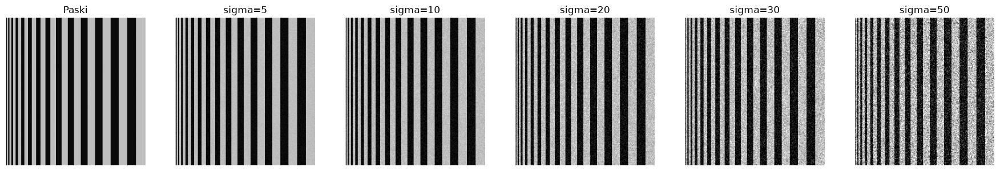

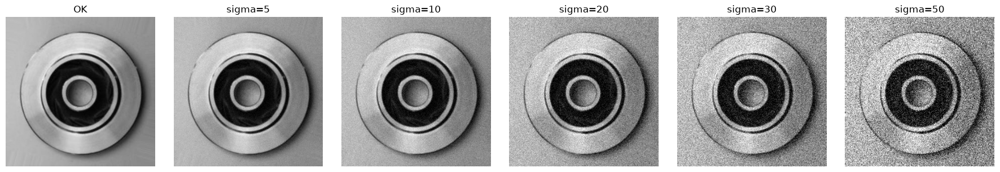

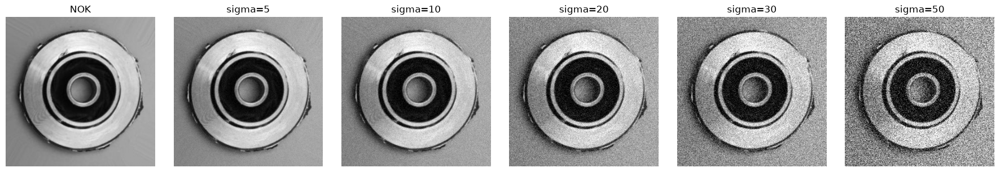

In [19]:
def add_gauss(img, sigma):
    noise = rng.normal(0, sigma, img.shape)
    out = img.astype(np.float32) + noise
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


sigmas = [5, 10, 20, 30, 50]
gauss = {}

for name, img in imgs.items():
    outs = []

    for sigma in sigmas:
        out = add_gauss(img, sigma)
        outs.append(out)

    gauss[name] = outs
    titles = [name] + [f"sigma={s}" for s in sigmas]
    show([img] + outs, titles)

Opisz swoje spostrzeżenia

Przy $σ$=5 szum jest delikatny, a szczegóły obrazów pozostają czytelne.
Wraz ze wzrostem σ coraz wyraźniej widać ziarnistość na tle,
powierzchni tarcz oraz paskach. Przy σ=50 główne kontury nadal
są widoczne, ale drobne szczegóły i nierówności brzegu tarczy NOK
trudniej odróznić od zakłóceń.

### b) Szum Poissona   
  
  Szum Poissona jest otrzymywany przez zastąpienie wartości oryginalnej $f_{ij}$ przez wartość losową o rozkładzie Poissona.  

Należy dodać szum Poissona dla 5 różnych wartości parametru $λ$.

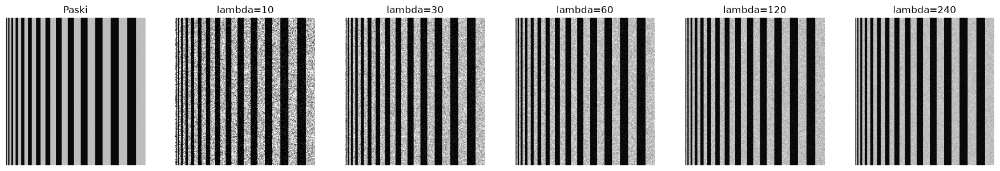

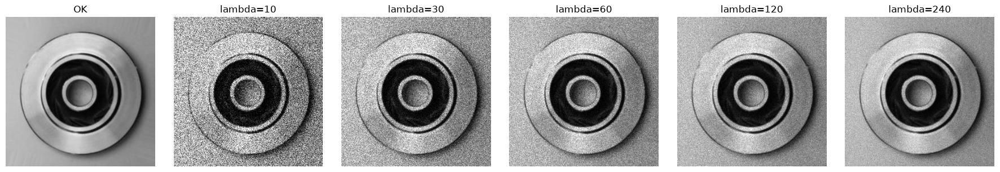

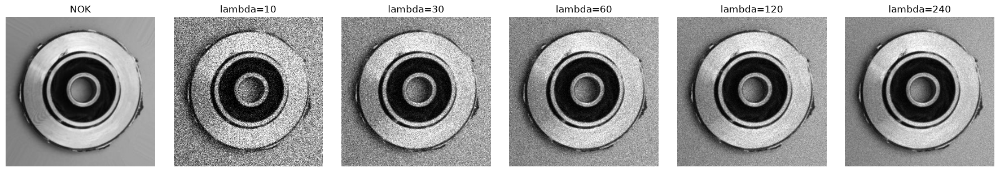

In [20]:
def add_poisson(img, lam):
    rate = img.astype(np.float32) / 255 * lam
    out = rng.poisson(rate) * 255.0 / lam
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


lams = [10, 30, 60, 120, 240]
poisson = {}

for name, img in imgs.items():
    outs = []

    for lam in lams:
        out = add_poisson(img, lam)
        outs.append(out)

    poisson[name] = outs
    titles = [name] + [f"lambda={v}" for v in lams]
    show([img] + outs, titles)

OPisz swoje spostrzeżenia

Przy $λ$=10 obrazy są silnie ziarniste. Zakłócenia są szczególnie
widoczne na jasnych paskach i jasnej powierzchni tarcz.
Wraz ze wzrostem $λ$ ziarnistość maleje, a szczegóły stają się
czytelniejsze. Przy $λ$=240 obrazy najbardziej przypominają
oryginały, chociaz nadal widać delikatny szum.

### c) Szum Salt and Pepper. 
  
Szum w którym określona ilość pikselii jest zamieniana według rozkładu jednostajnego i ich wartość $f_{ij}$ jest zamieniana na 0 (czarny) lub biały (255) z prawdopodobieństwem $\frac{1}{2}$.  
  
Należy dodać szum Salt and Pepper dla 5%, 15%, 25%, 35% i 50% pikseli zamienionych na biały i/lub czarny.  


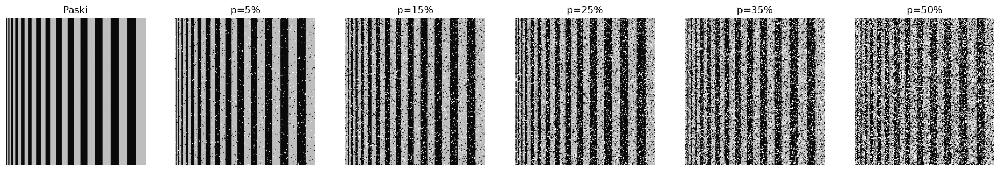

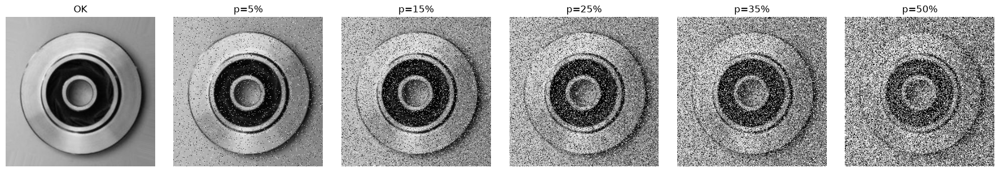

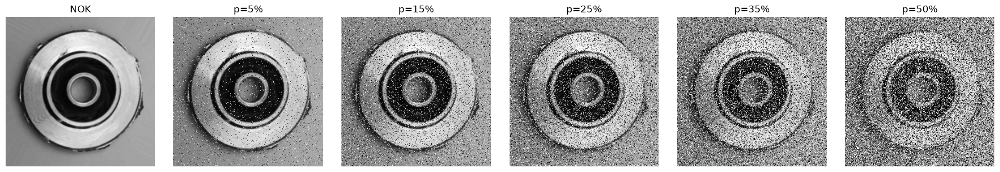

In [21]:
def add_sp(img, p):
    out = img.copy()
    n = round(p * img.size)
    ids = rng.choice(img.size, size=n, replace=False)
    out.flat[ids] = rng.choice([0, 255], size=n)
    return out


ps = [0.05, 0.15, 0.25, 0.35, 0.50]
sp = {}

for name, img in imgs.items():
    outs = []

    for p in ps:
        out = add_sp(img, p)
        outs.append(out)

    sp[name] = outs
    titles = [name] + [f"p={p:.0%}" for p in ps]
    show([img] + outs, titles)

Opisz swoje spostrzeżenia

Na obrazach pojawiają się czarne i białe punkty. Przy 5% są one
rozproszone i nie utrudniają znacznie rozpoznania szczegółów.
Wraz ze wzrostem udziału zaszumionych pikseli punkty coraz mocniej
zasłaniają paski i powierzchnię tarcz. Przy 50% ogólny kształt tarcz
nadal jest rozpoznawalny, ale ocena drobnych wad i najcieńszych
pasków jest znacznie trudniejsza.

## Zadanie 2 - Filtrowanie 

Dla obrazów otrymanyh w zadaniu 1 wykonaj poniższe zadania. 
  
### a) Filtr Butterworth. 
  
Zastosuj filrt Butterworth do wszystkich obrazów

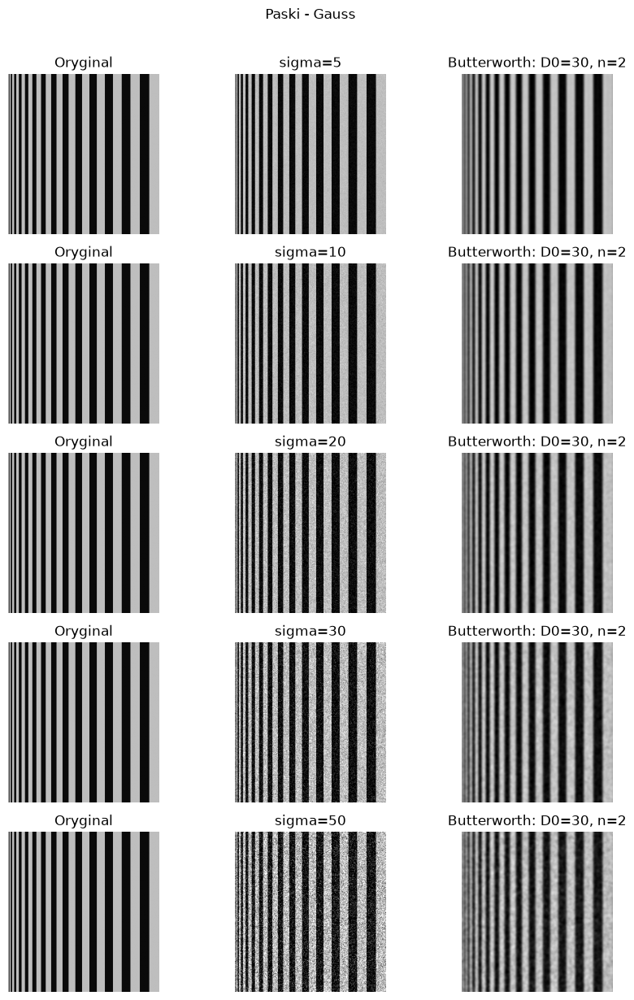

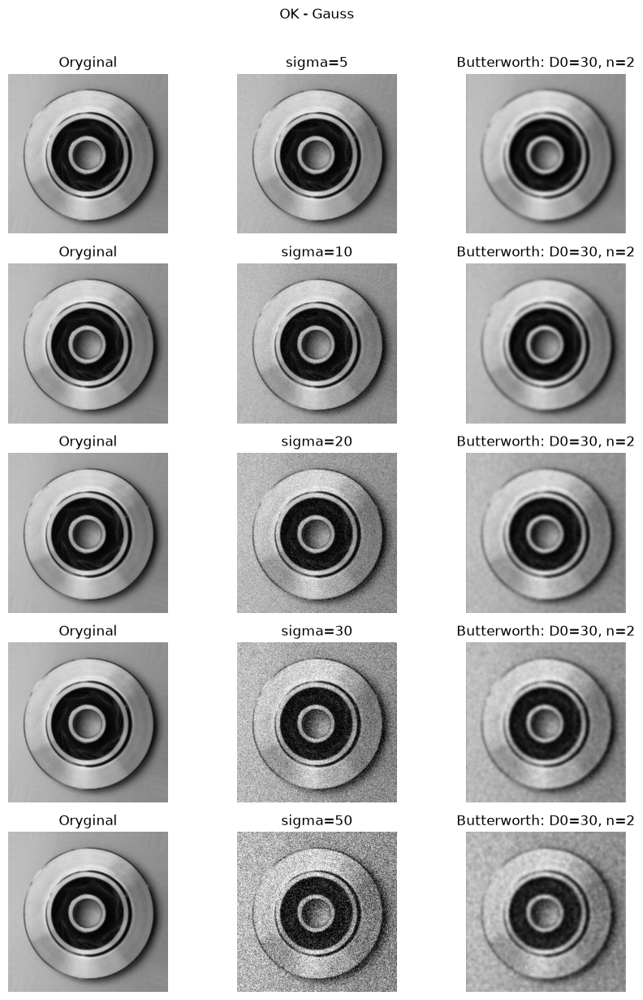

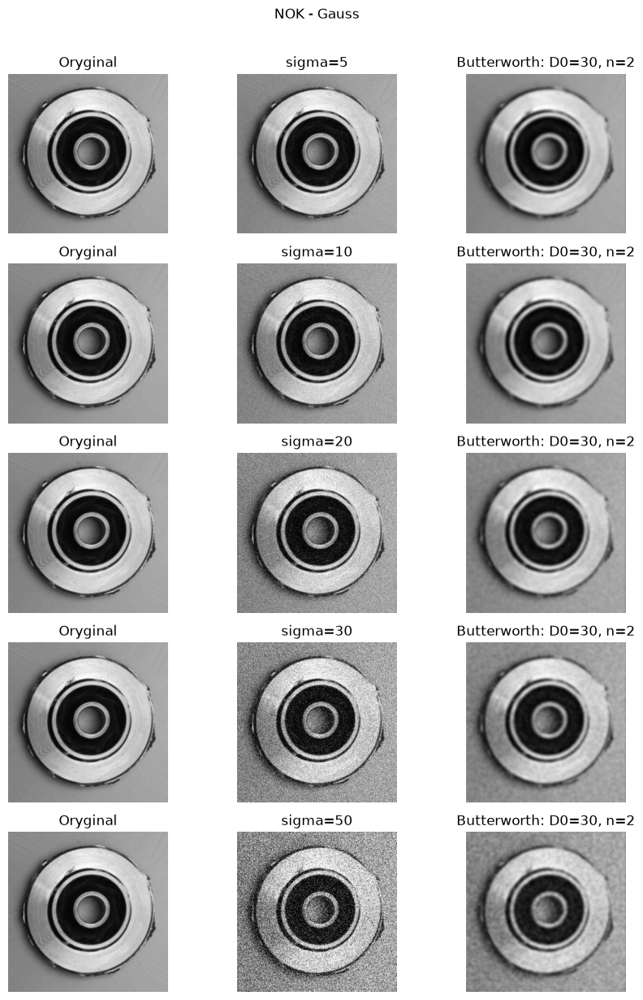

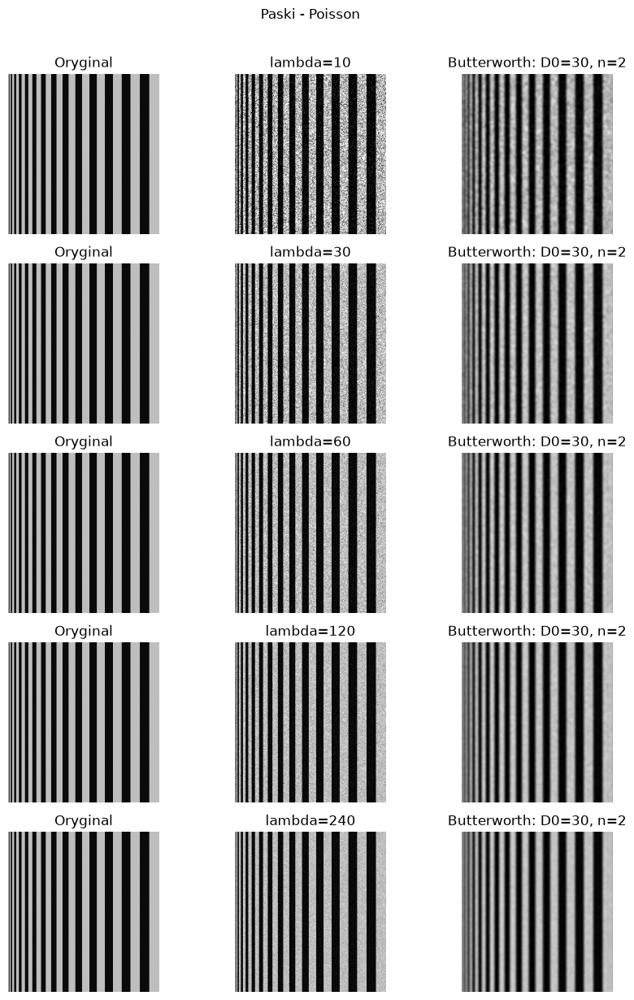

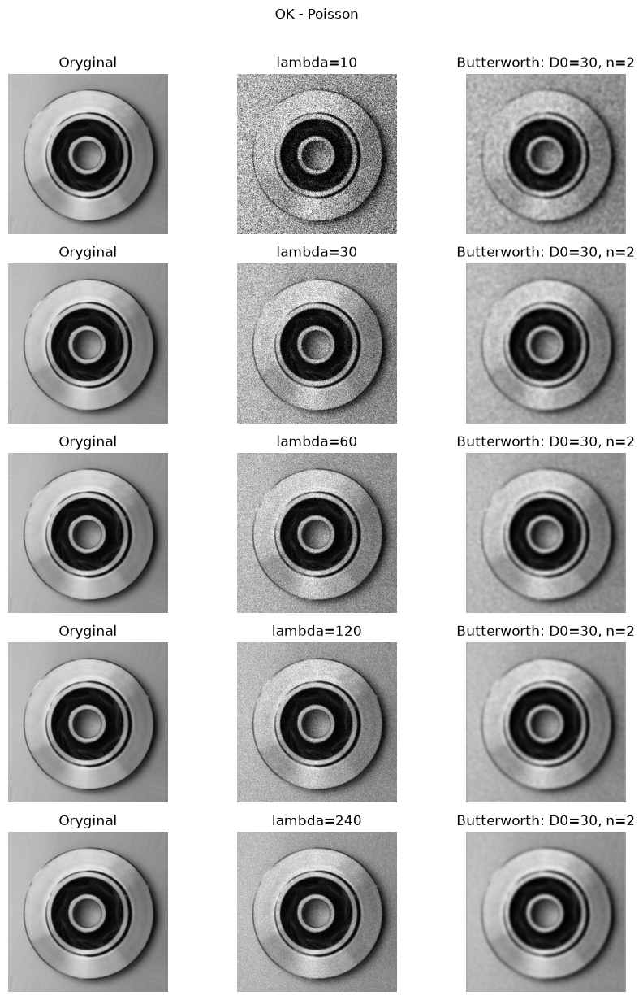

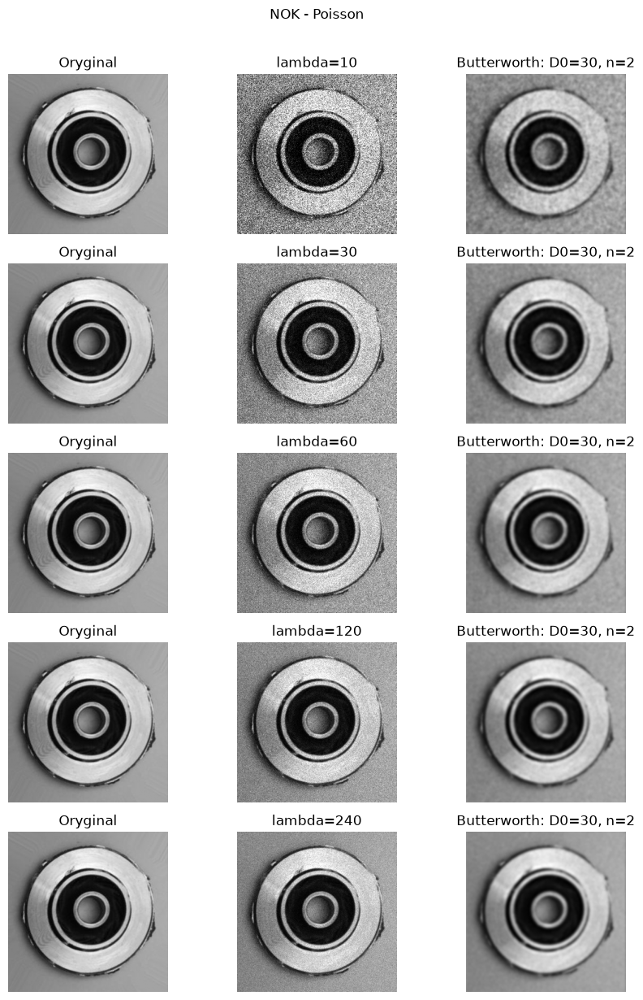

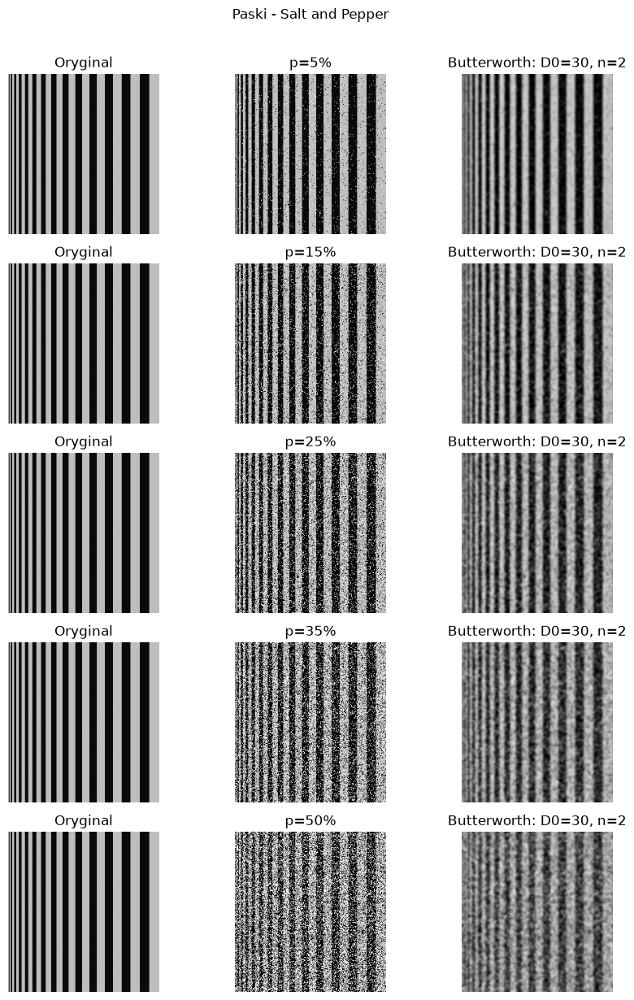

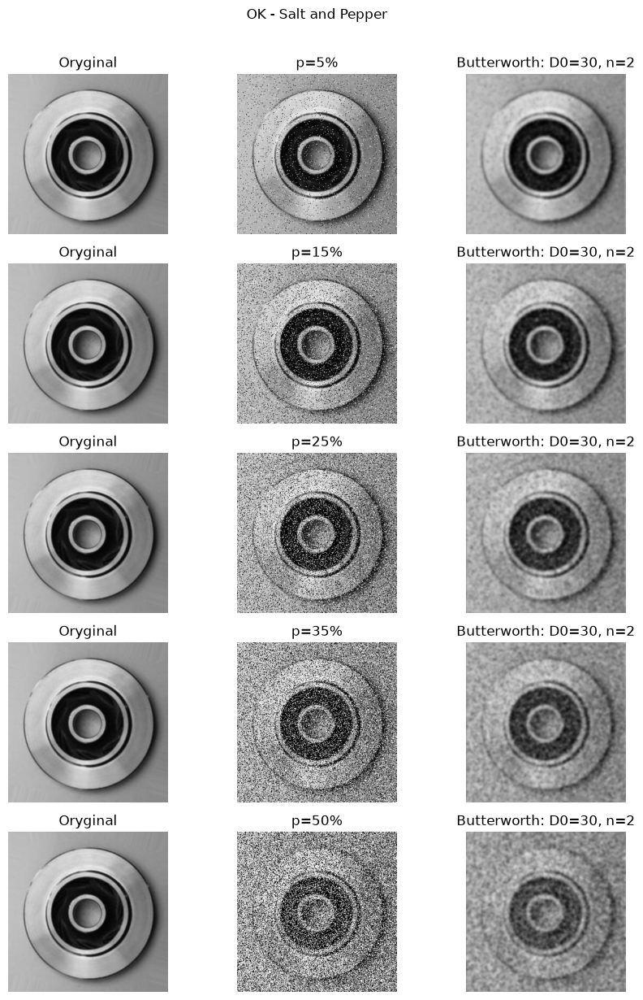

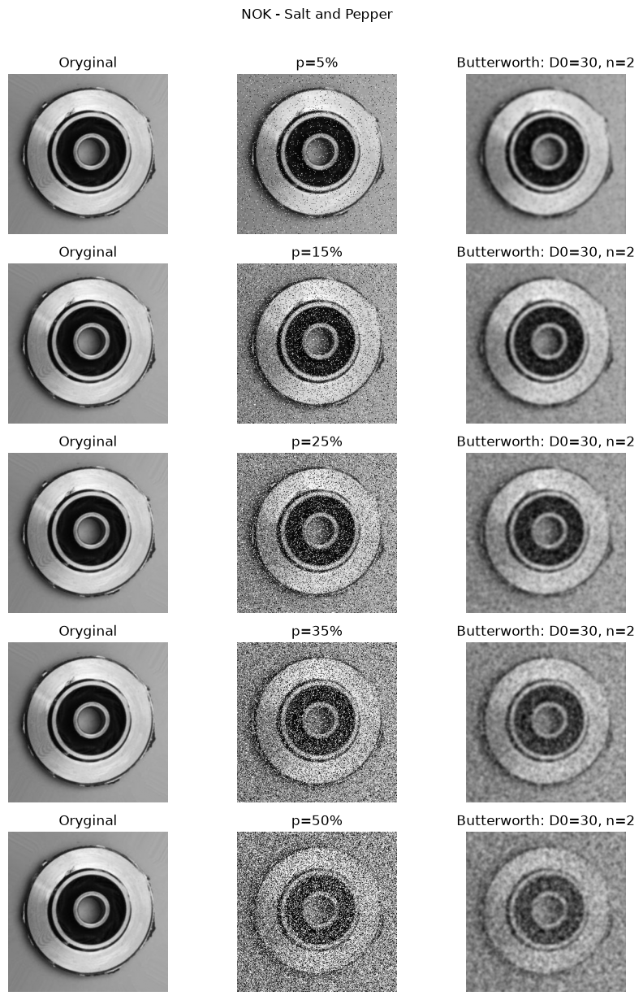

In [22]:
sets = [
    ("Gauss", gauss, [f"sigma={v}" for v in sigmas]),
    ("Poisson", poisson, [f"lambda={v}" for v in lams]),
    ("Salt and Pepper", sp, [f"p={v:.0%}" for v in ps])
]


def filter_all(func, vals, titles):
    for kind, data, levels in sets:
        for name, outs in data.items():
            cols = len(vals) + 2
            fig, axes = plt.subplots(
                len(outs), cols, figsize=(3 * cols, 2.5 * len(outs))
            )
            fig.suptitle(f"{name} - {kind}")

            for i, (src, level) in enumerate(zip(outs, levels)):
                row = [imgs[name], src]
                for val in vals:
                    row.append(func(src, val))

                names = ["Oryginal", level] + titles
                for ax, img, title in zip(axes[i], row, names):
                    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
                    ax.set_title(title)
                    ax.axis("off")

            plt.tight_layout(rect=(0, 0, 1, 0.97))
            plt.show()


def butter(img, d0, n=2):
    h, w = img.shape
    y, x = np.indices((h, w))
    d = np.hypot(x - w // 2, y - h // 2)
    mask = 1 / (1 + (d / d0) ** (2 * n))

    spec = np.fft.fftshift(np.fft.fft2(img))
    out = np.fft.ifft2(np.fft.ifftshift(spec * mask)).real
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


filter_all(butter, [30], ["Butterworth: D0=30, n=2"])

Opisz swoje spostrzeżenia

Filtr Butterwortha zmniejszył ziarnistość obrazów z szumem Gaussa
i Poissona, ale rozmył krawędzie oraz zmniejszył kontrast najcienszych
pasków. Przy szumie Salt and Pepper punkty zostały rozmyte,
a na obrazie pozostały widoczne zakłócenia. Główne kontury tarcz
pozostały czytelne, lecz drobne szczegóły były słabiej widoczne.

### b) Filtr Gaussowski. 
  
Zastosuj filrt Gaussowski do wszystkich obrazów dla 3 różnych warotści $σ$

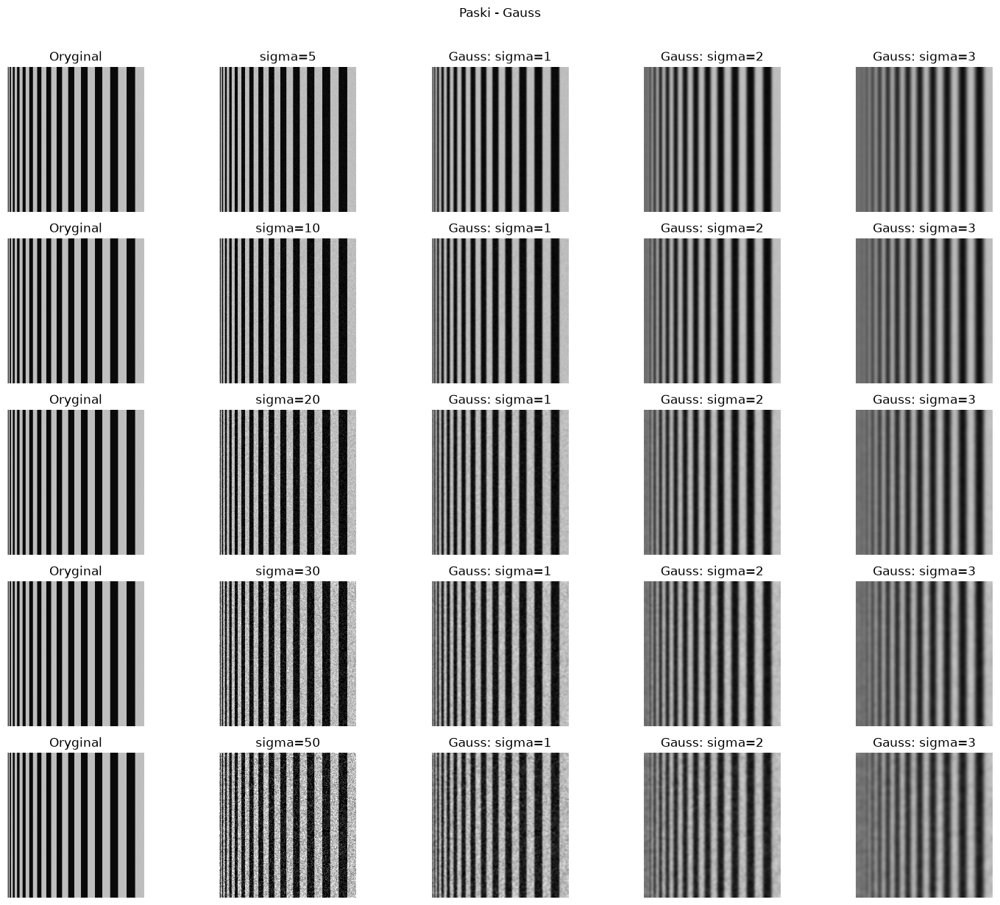

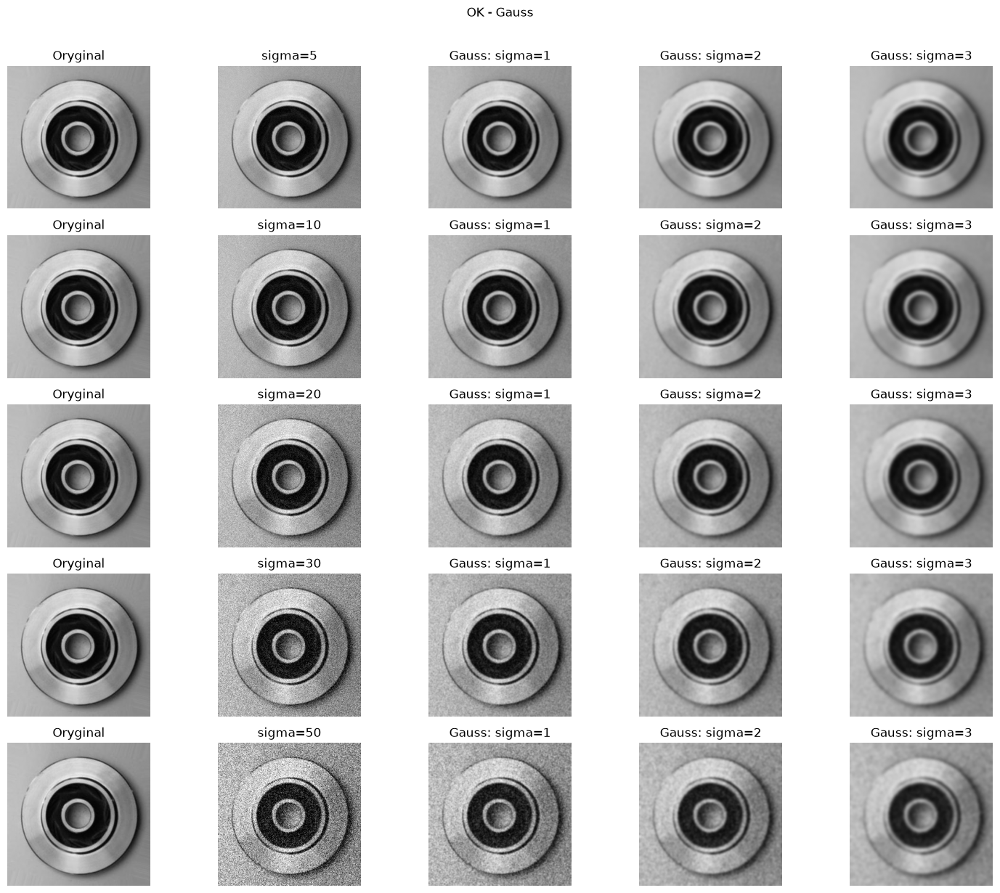

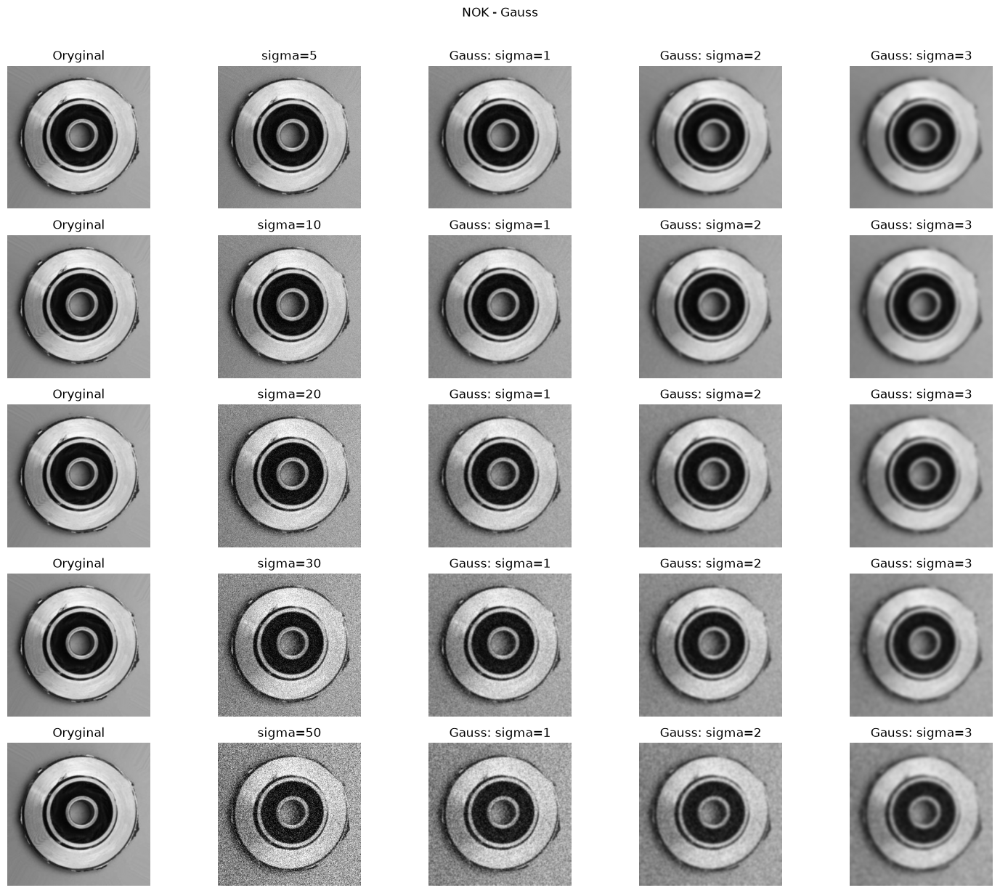

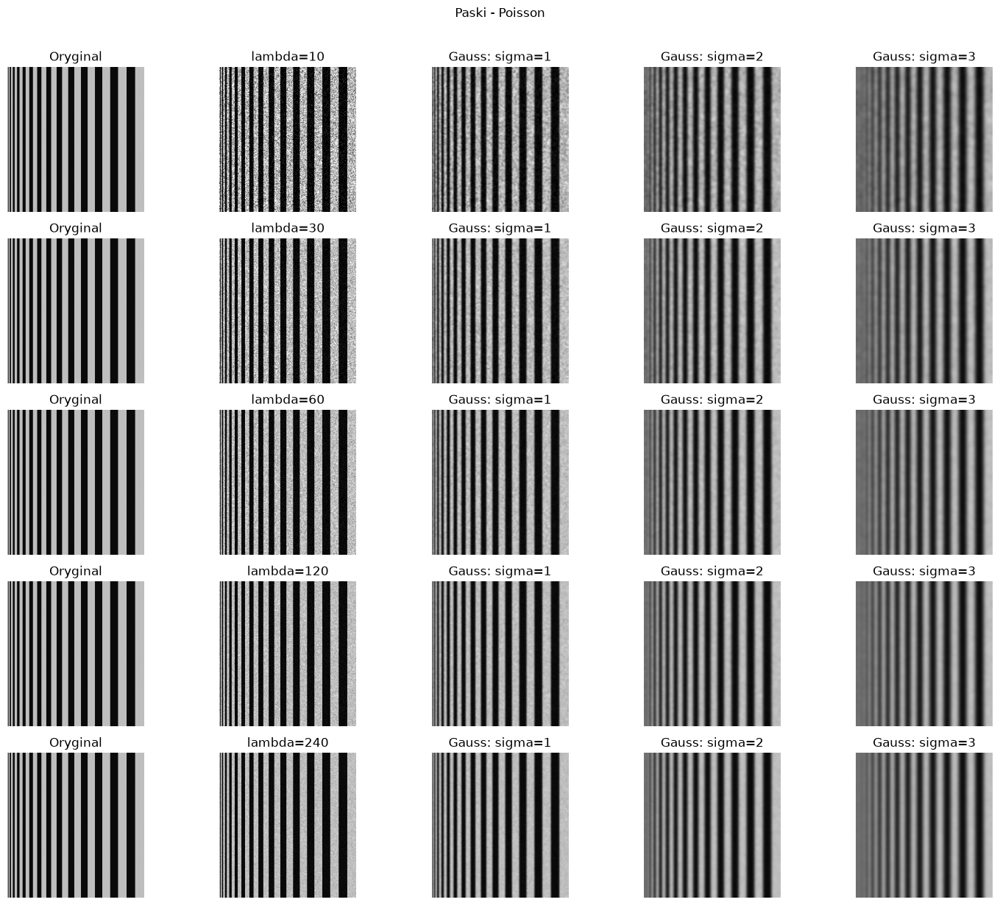

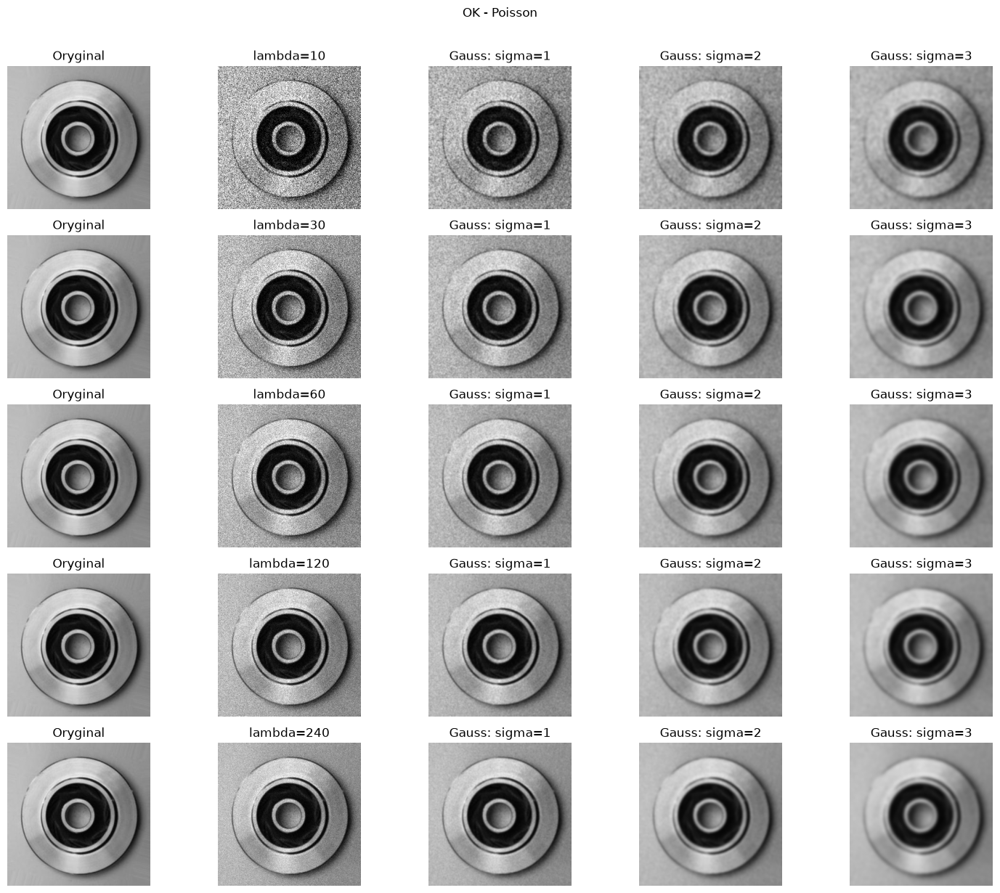

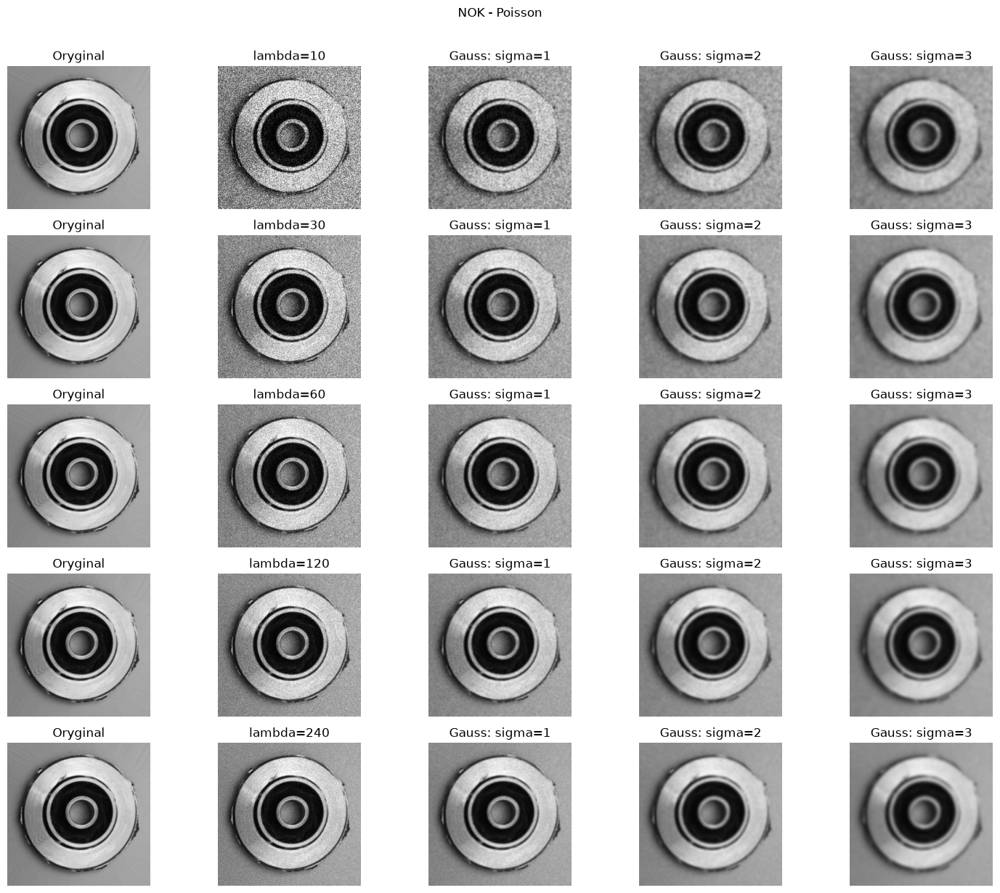

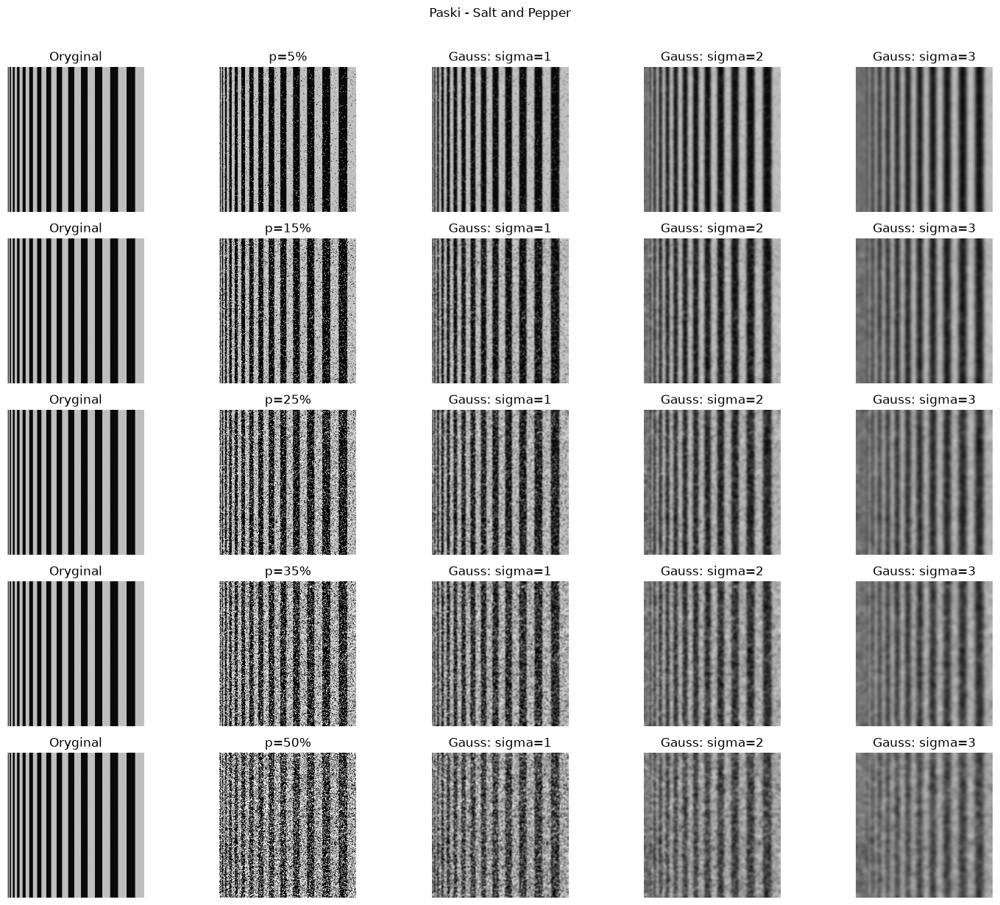

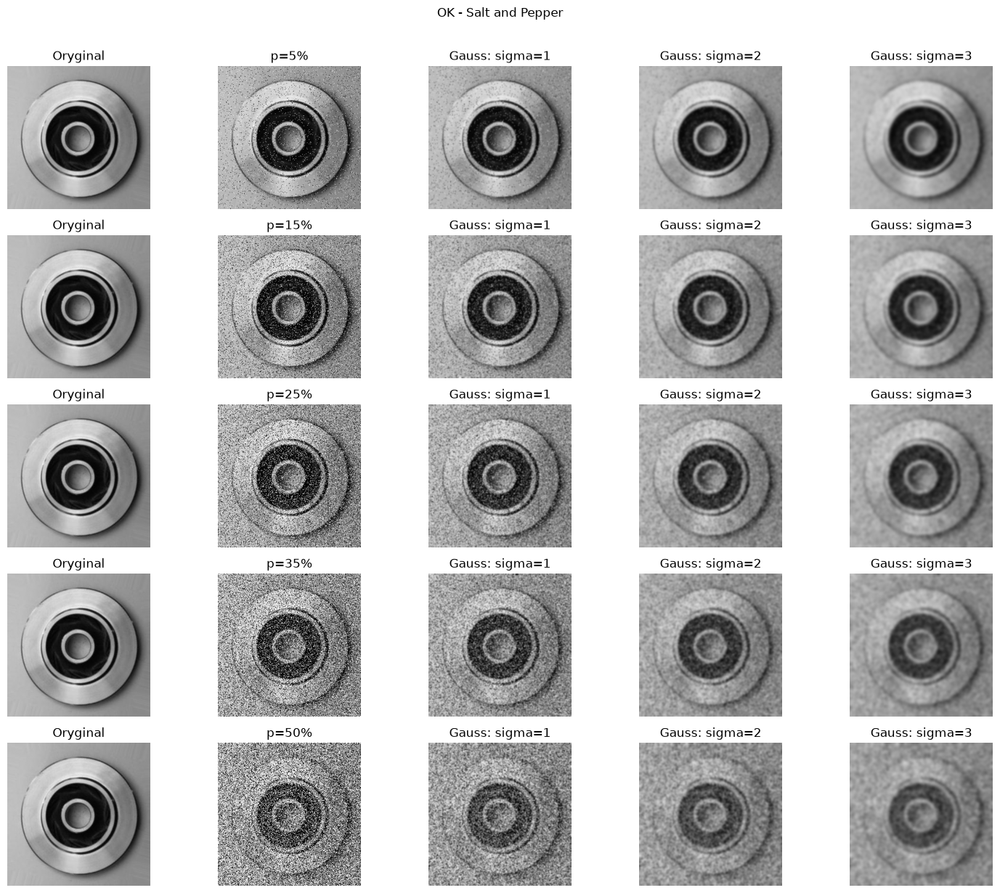

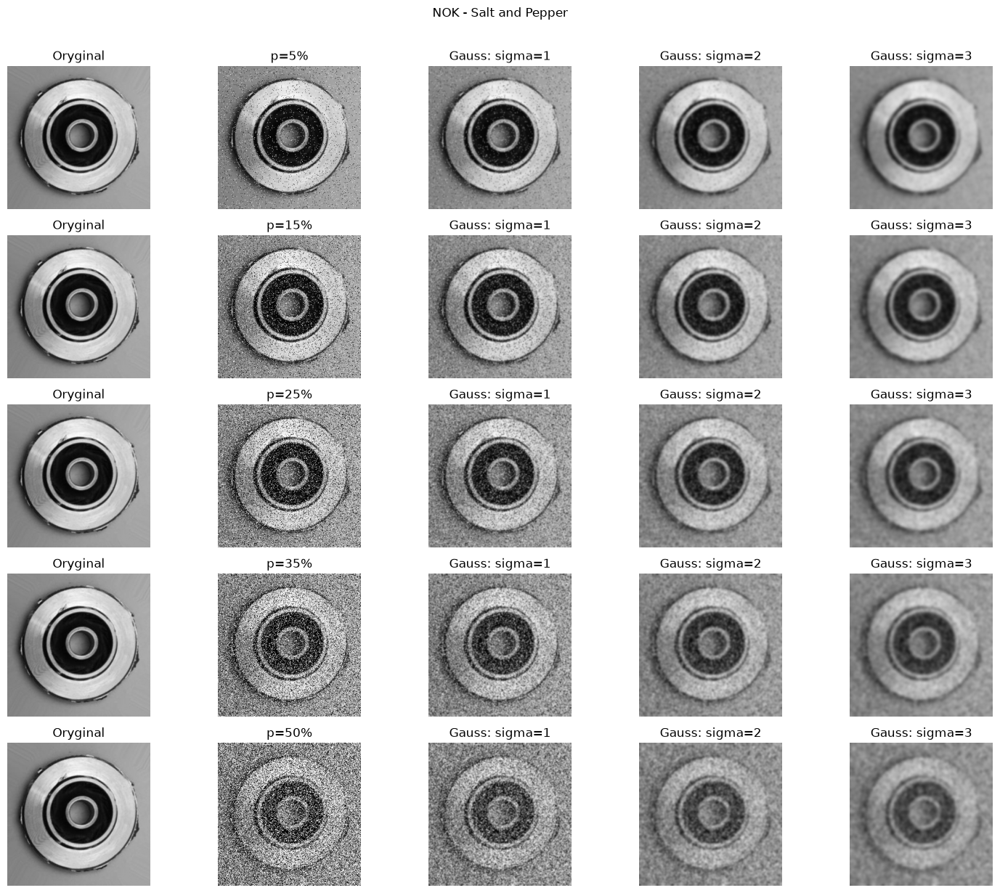

In [23]:
def gaussian(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma)


filter_all(
    gaussian,
    [1, 2, 3],
    ["Gauss: sigma=1", "Gauss: sigma=2", "Gauss: sigma=3"]
)

Filtr Gaussowski zmniejszył ziarnistość obrazów z szumem Gaussa
i Poissona. Zwiększanie sigma od 1 do 3 dawało silniejsze
wygładzenie, ale rozmywało krawędzie tarcz i zmniejszało
czytelność cienkich pasków. Przy szumie Salt and Pepper
czarne i białe punkty zostały rozmyte do plamek, przez co
zakłócenia nadal były widoczne.

### c) Filtr Medianowy. 
  
Zastosuj filrt Medianowy do wszystkich obrazów dla 3 wartości okna (5x5, 11x11, 21x21)

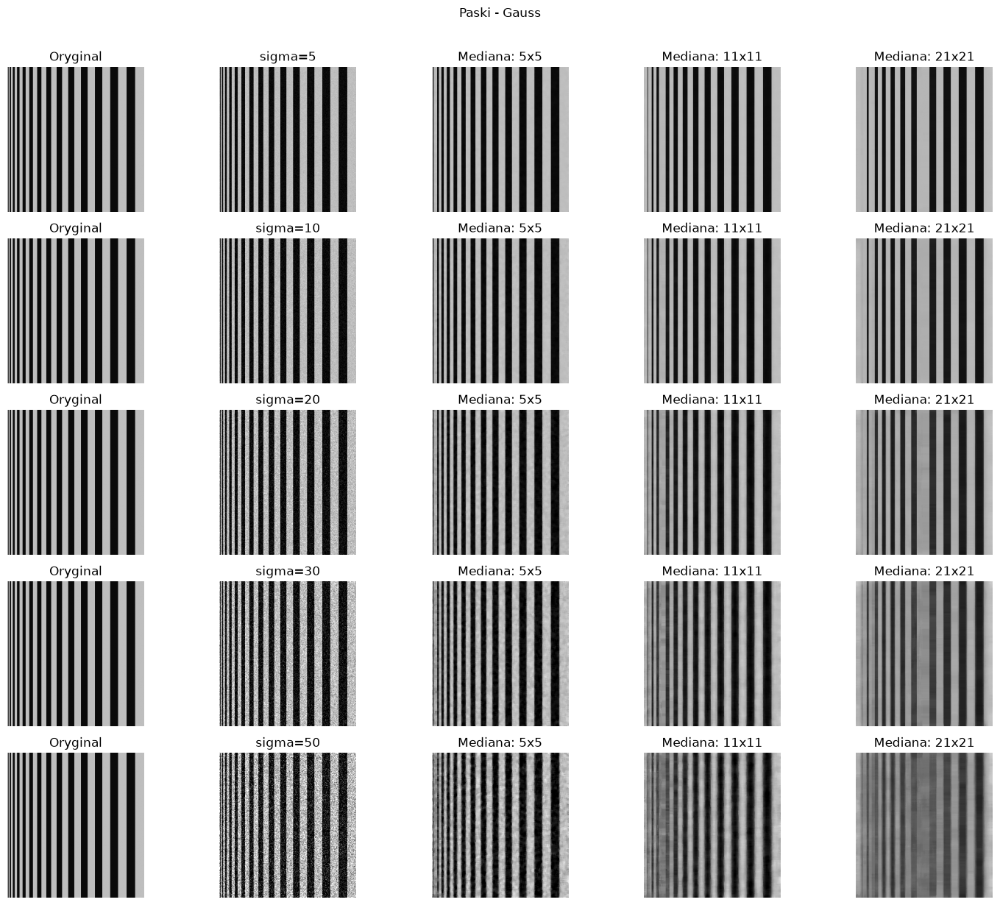

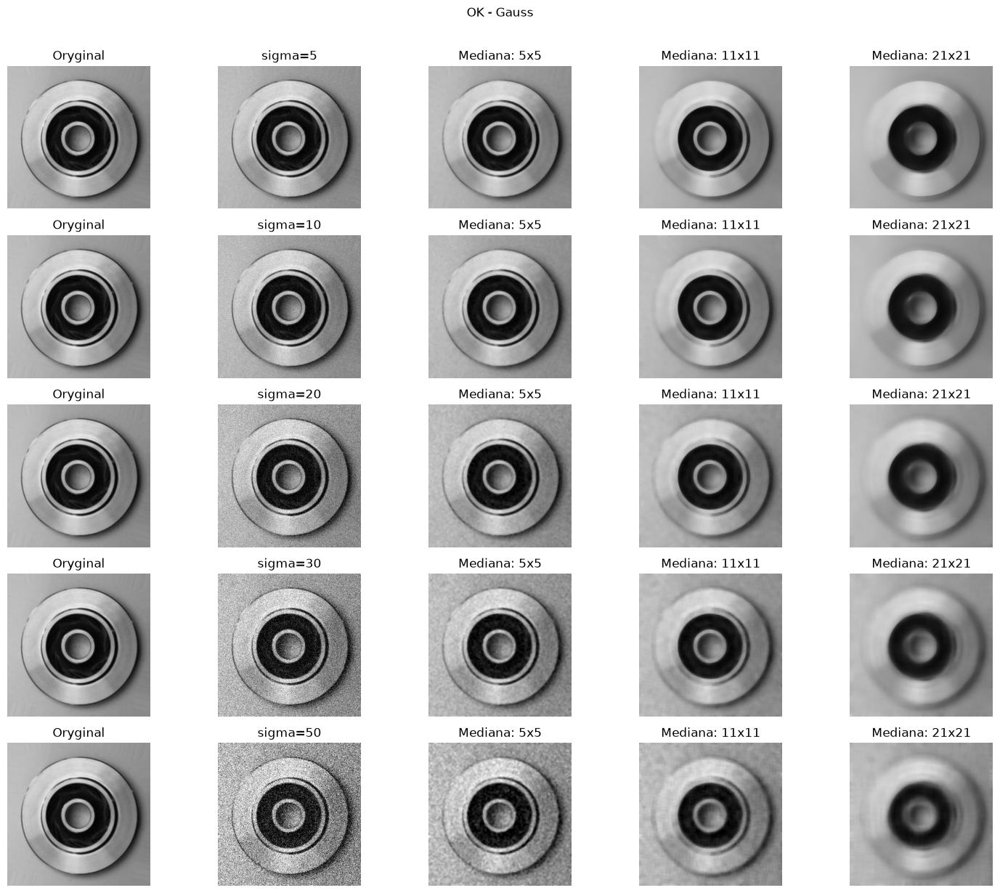

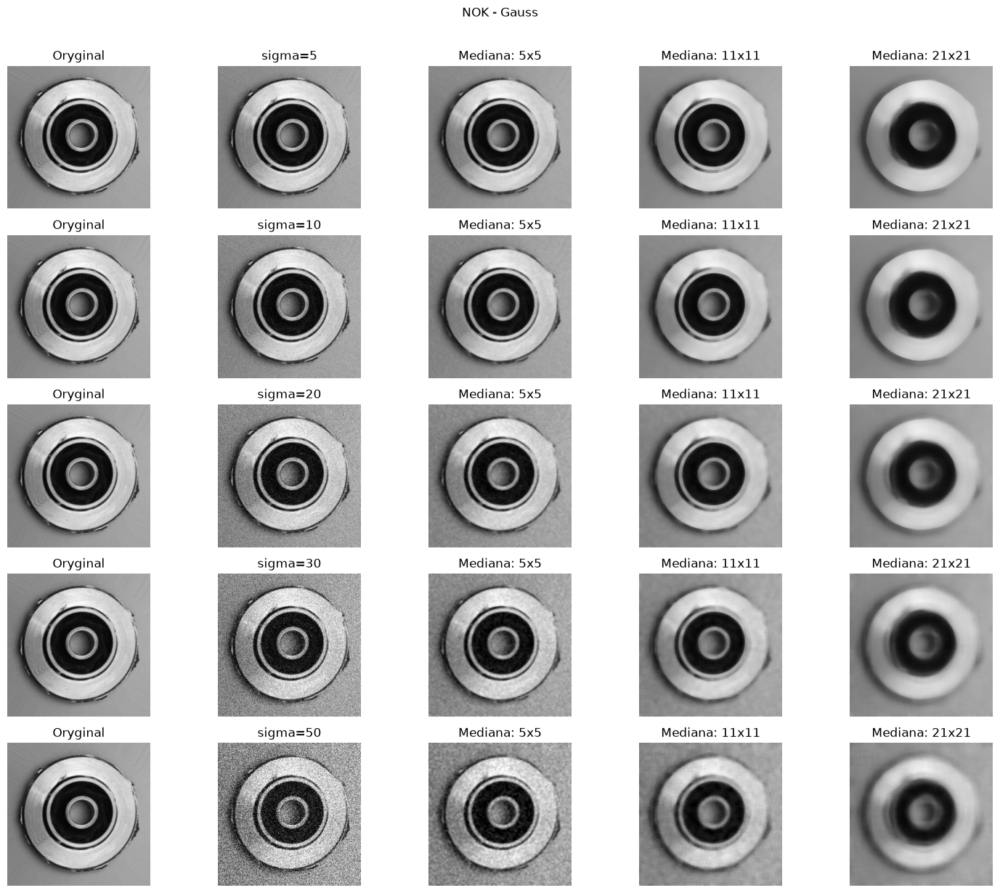

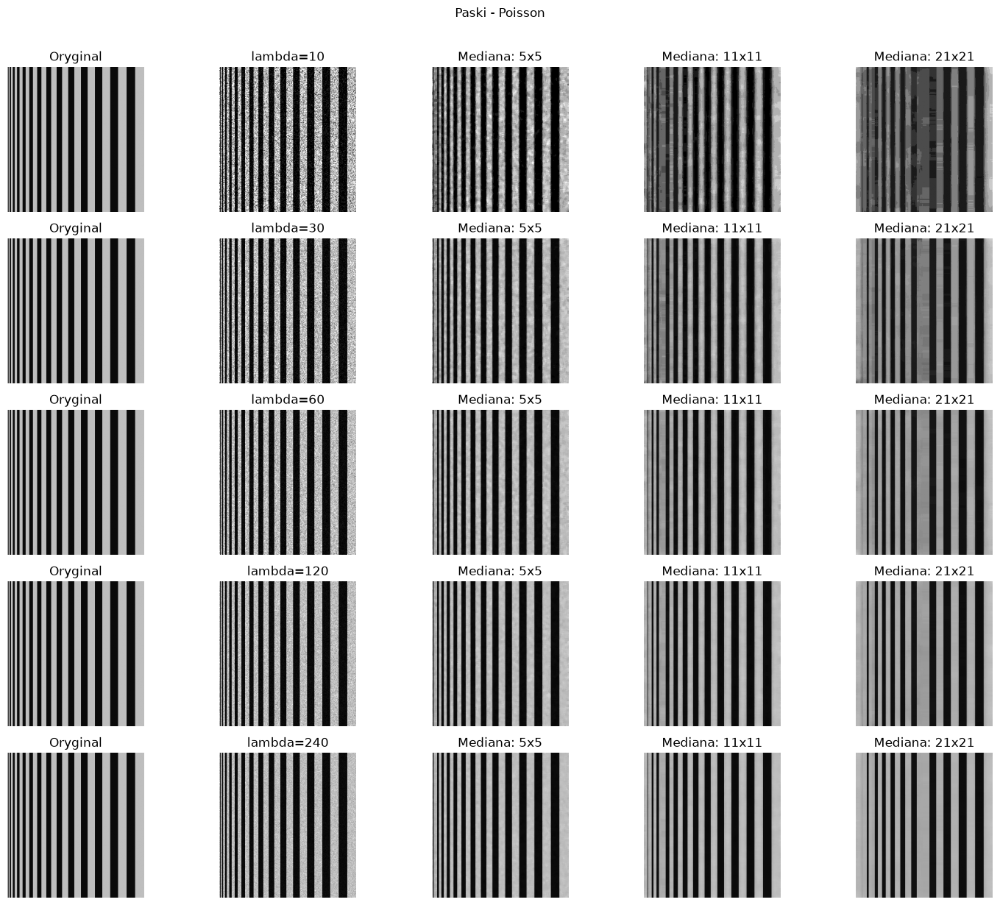

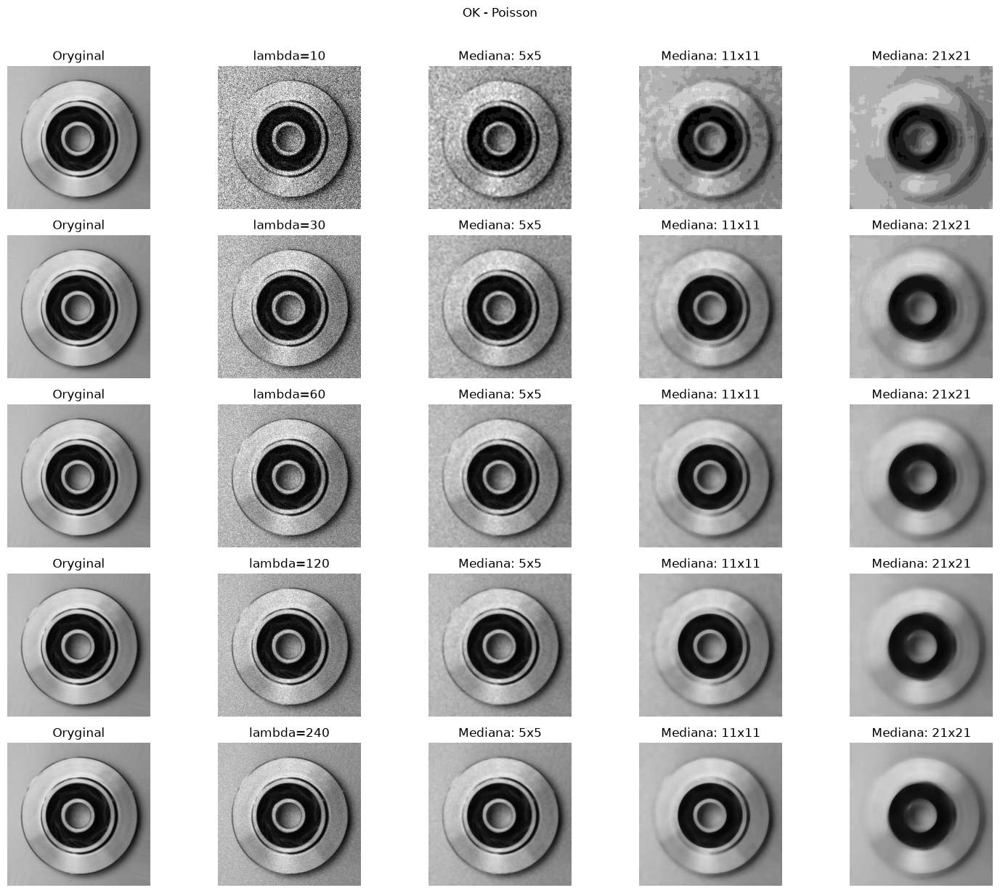

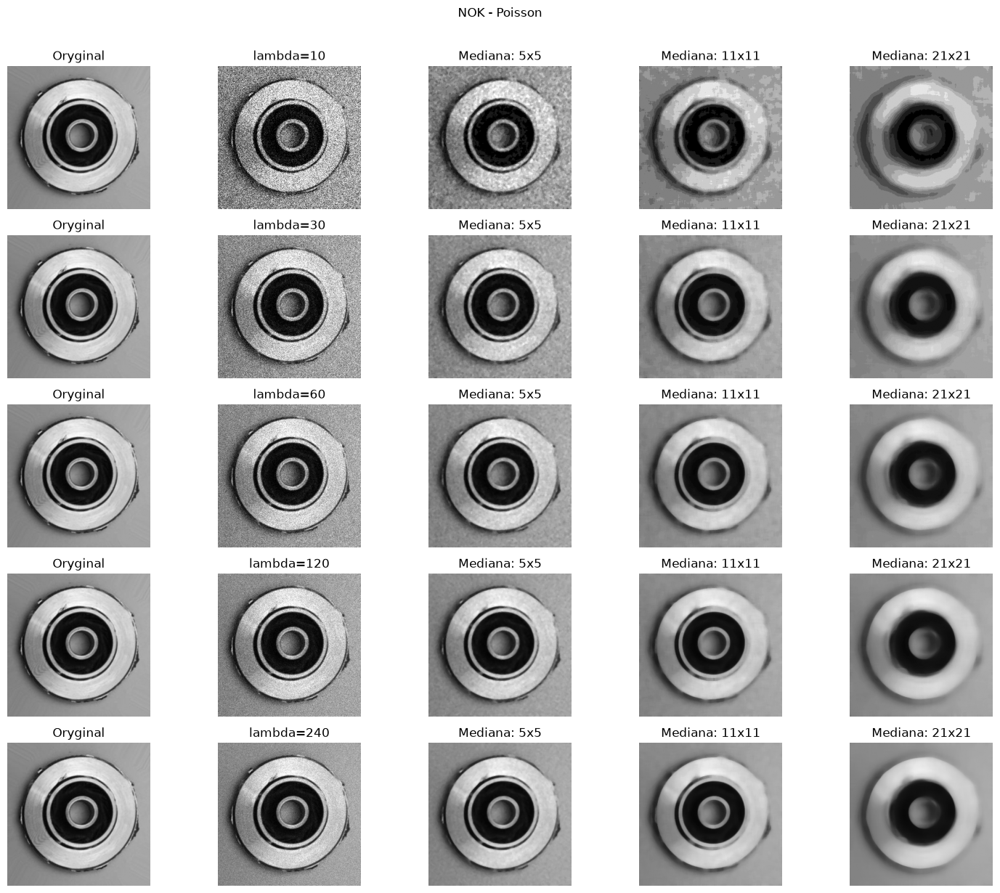

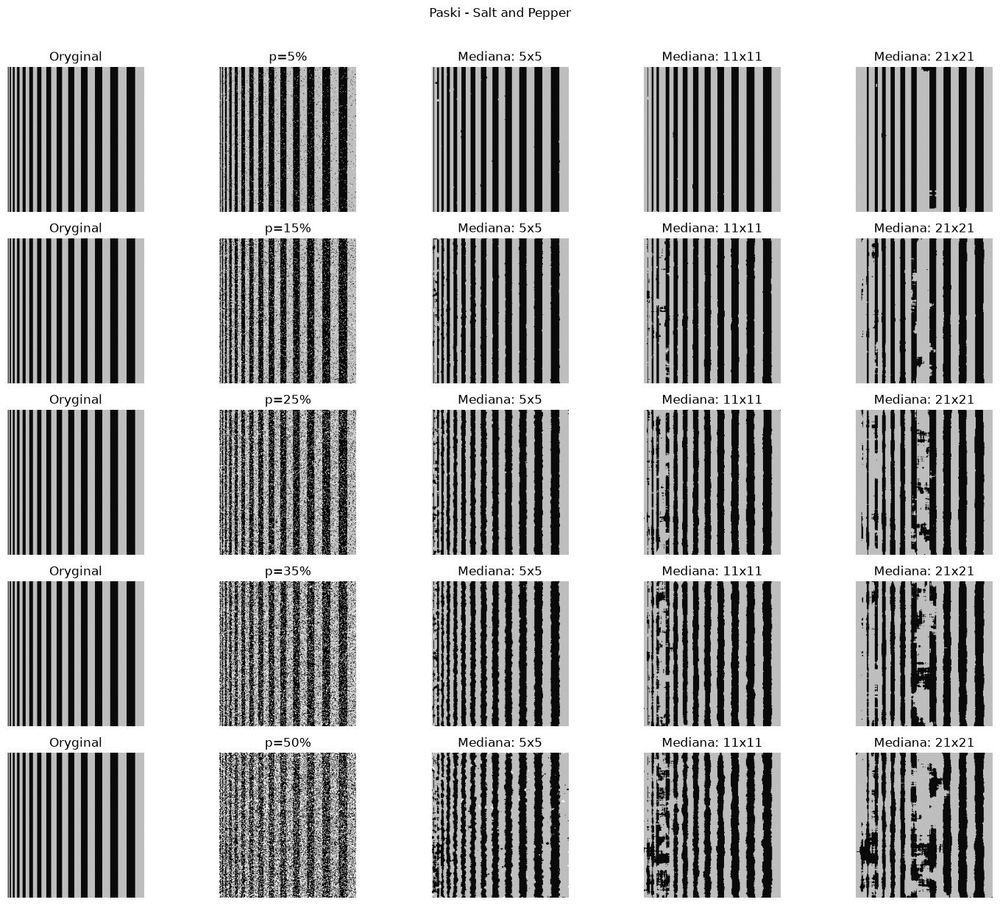

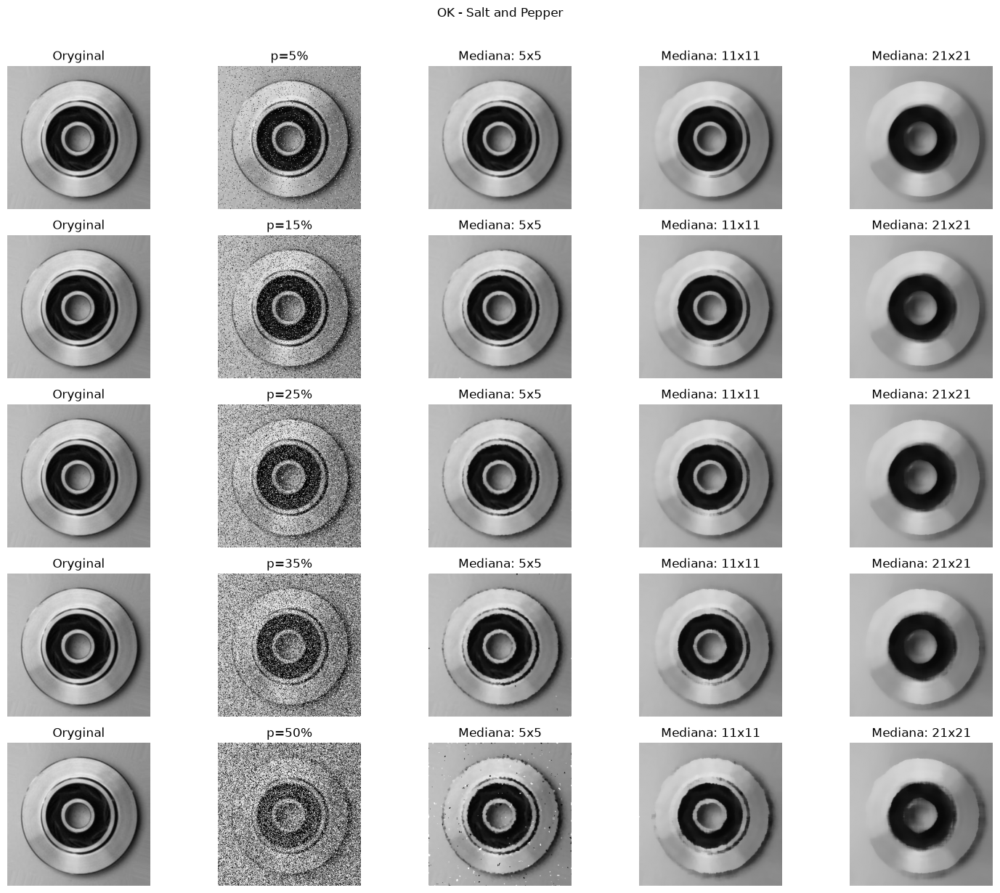

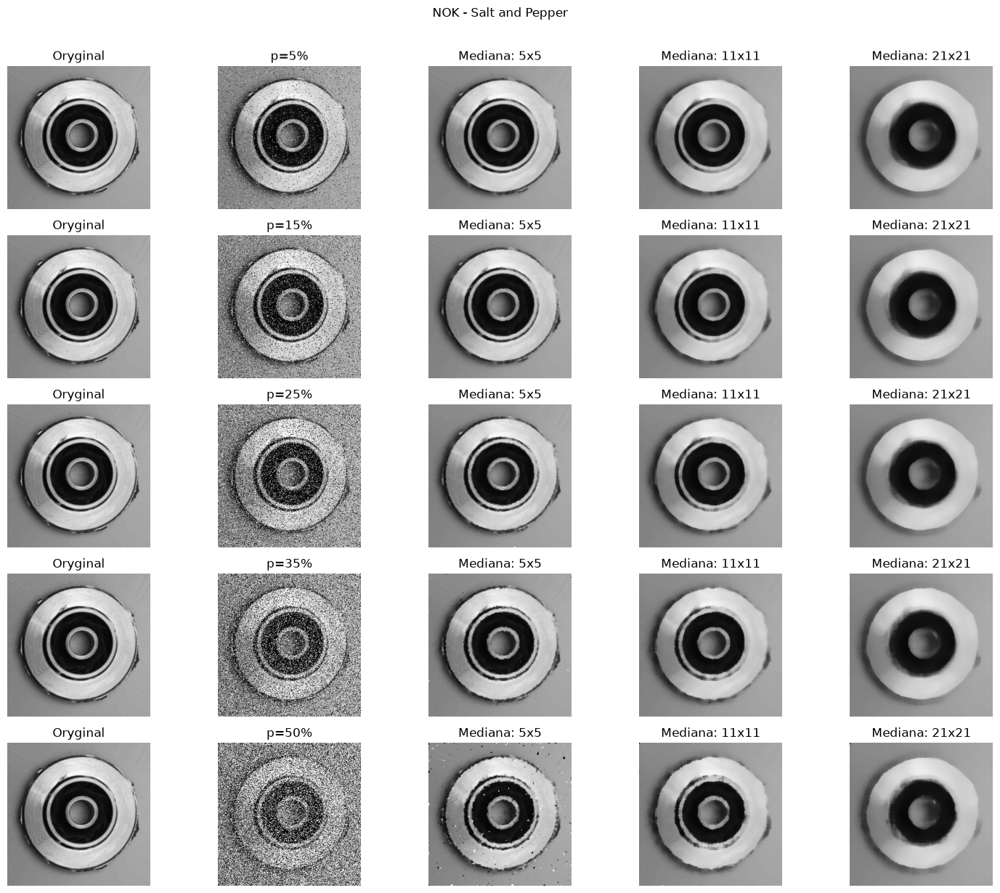

In [24]:
filter_all(
    cv2.medianBlur,
    [5, 11, 21],
    ["Mediana: 5x5", "Mediana: 11x11", "Mediana: 21x21"]
)

Filtr medianowy skutecznie usuwał szum Salt and Pepper.
Okno 5x5 zachowywało najwięcej szczegółów. Zwiększanie okna
do 11x11 i 21x21 silniej wygładzało obraz, ale usuwało cienkie
paski i drobne elementy tarcz. Filtr ograniczał takze szum
Gaussa i Poissona, jednak przy duzych oknach widoczna była
utrata szczegółów i zmiana kształtu krawędzi.

Opisz swoje spostrzeżenia. Czy wszystkie filtry tak samo zachowują krawęzie? 

Zwiększanie sigma filtra Gaussowskiego silniej wygładzało szum,
ale powodowało większe rozmycie konturów tarcz i zanikanie cienkich
pasków. Przy szumie Salt and Pepper pozostawały rozmyte plamki.

Filtr medianowy najskuteczniej usuwał szum Salt and Pepper.
Okno 5x5 zachowywało więcej szczegółów, natomiast okna 11x11
i 21x21 silniej zmieniały drobne elementy oraz usuwały cienkie paski.

Filtry nie zachowują krawędzi jednakowo. Butterworth i Gauss
rozmywają przejścia jasności. Mediana lepiej zachowuje ostre
granice większych obiektów, ale przy duzym oknie zmienia ich
kształt i usuwa niewielkie szczegóły.

## Zadanie 3 - Wyznaczanie krawędzi

Cztery (dwie prawidłowe tarcze i dwie uszkodzone) dowolne obrazy pozyskane w trakcie laboratorium 2 zamień na obrazy monochromatyczne, a następnie wykonaj poniższe polecenia. 

### a) Detekcja krawędzi metodą Sobela. 
  
Zastosuj filtr Sobela do wybranych obrazów

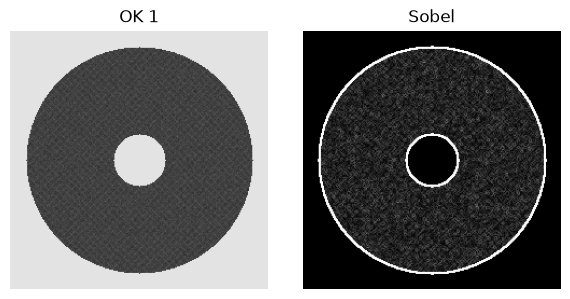

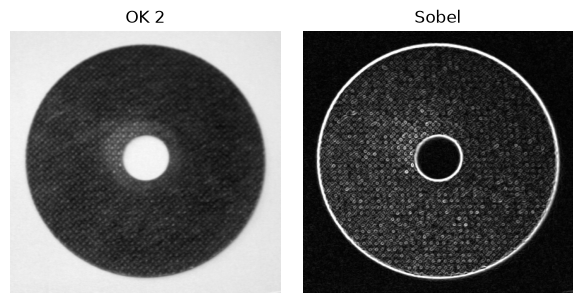

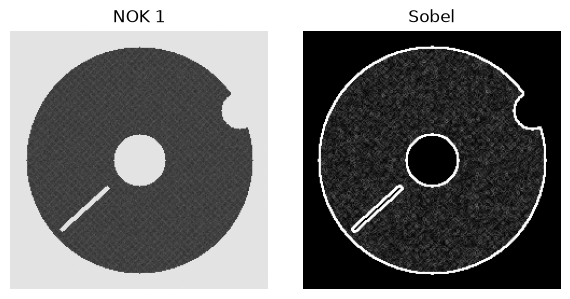

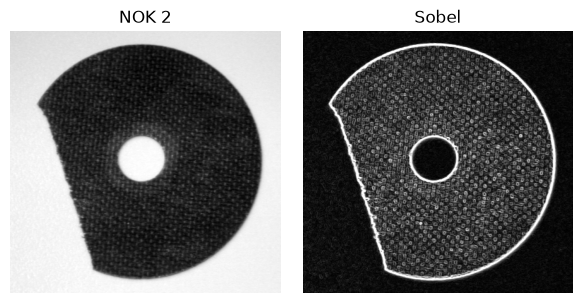

In [25]:
path = Path("../../photos")

edge_imgs = {
    "OK 1": load(path / "tarcza_wzorzec.png"),
    "OK 2": load(path / "grinder_good.bmp"),
    "NOK 1": load(path / "tarcza_badana.png"),
    "NOK 2": load(path / "grinder_cut.bmp")
}

for name, img in edge_imgs.items():
    dx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    dy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    out = cv2.magnitude(dx, dy)
    out = cv2.convertScaleAbs(out)

    show([img, out], [name, "Sobel"])

Filtr Sobela wyraźnie zaznaczył zewnętrzne kontury tarcz,
otwory oraz brzegi uszkodzeń. Widoczne są wycięcia,
a na obrazie NOK 1 takze pęknięcie. Kontury są stosunkowo
grube. Filtr uwidocznił równiez fakturę powierzchni,
szczególnie na zdjęciach BMP.

### b) Detekcja krawędzi metodą Laplace'a. 
  
Zastosuj filtr Laplace'a do wybranych obrazów

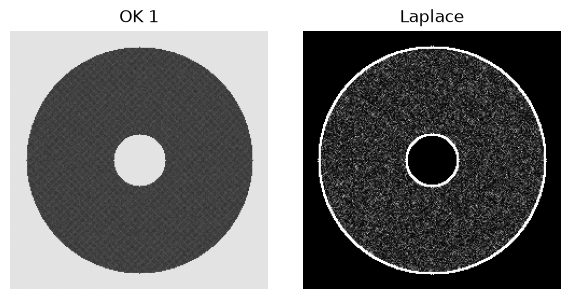

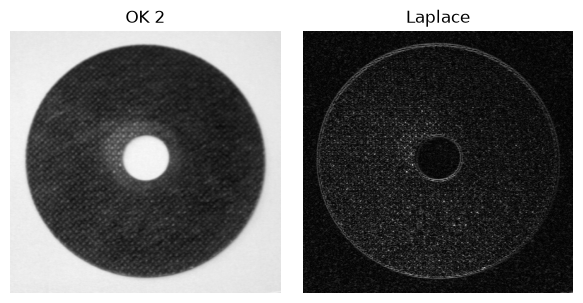

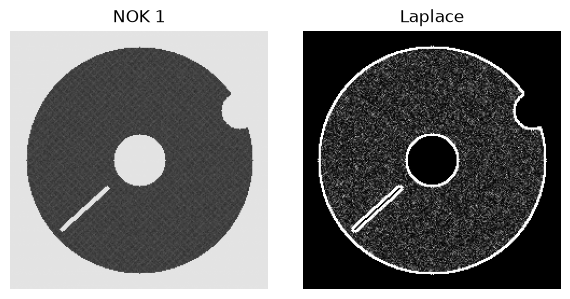

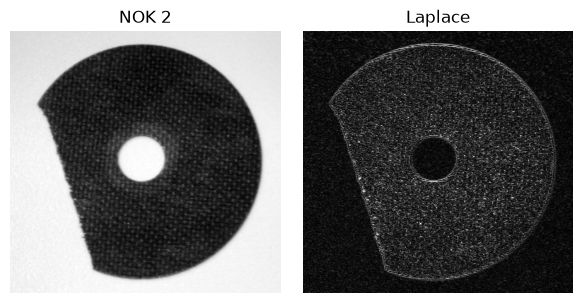

In [26]:
for name, img in edge_imgs.items():
    out = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
    out = cv2.convertScaleAbs(out)

    show([img, out], [name, "Laplace"])

Filtr Laplace'a zaznaczył kontury i uszkodzenia tarcz
syntetycznych, ale silnie uwidocznił takze drobne zmiany
jasności na ich powierzchni. Na zdjęciach BMP kontury
były słabsze i mniej czytelne niz w metodzie Sobela,
a faktura powierzchni utrudniała ocenę wyniku.

### c) Detekcja krawędzi metodą Canny'ego. 
  
Zastosuj filtr Canne'ego do wybranych obrazów

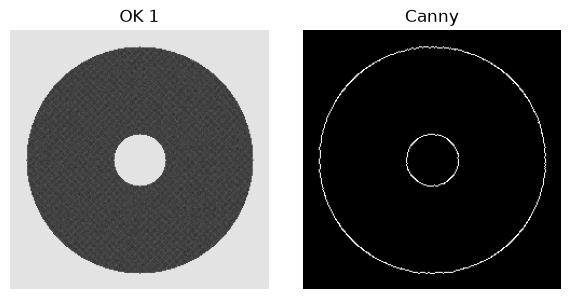

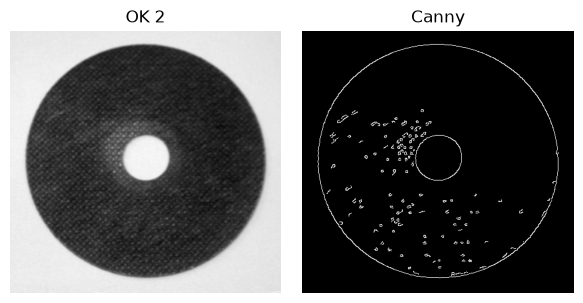

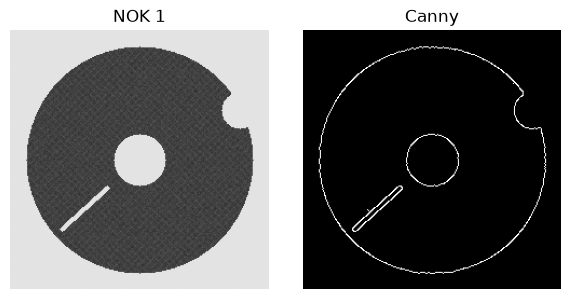

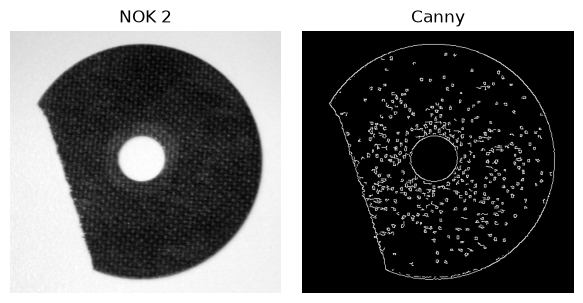

In [27]:
for name, img in edge_imgs.items():
    out = cv2.Canny(img, 100, 200)

    show([img, out], [name, "Canny"])

Metoda Canny'ego dała cienkie, białe krawędzie na czarnym tle.
Na obrazach syntetycznych zachowała obrys, otwór i brzegi
uszkodzeń, skutecznie pomijając fakturę powierzchni.
Na zdjęciach BMP pozostały dodatkowe krawędzie faktury,
szczególnie na obrazie NOK 2.

Opisz swoje spostrzeżenia po porównaniu 3 metod wyznaczania krawędzi.

Sobel wyraźnie zaznaczał główne kontury, ale dawał grubsze
krawędzie i uwidaczniał fakturę. Laplace silnie reagował
na drobne zmiany jasności, a na zdjęciach BMP dawał mniej
czytelne kontury. Canny tworzył najciensze krawędzie
i najlepiej oddzielał obrys od faktury na obrazach
syntetycznych. Na rzeczywistych zdjęciach nadal wykrywał
część struktury powierzchni.